# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent, HumanRuleAgent, EpsilonGreedyAgent, UCBAgent, ContextFreeUCBAgent, LinearGreedyAgent, LinearEpsilonGreedyAgent  # add your own agents here

In [2]:
import pandas as pd

def true_means_by_day(bay, n_days):
    info = bay.reveal()
    before = info["means"]
    after = info.get("means_after_change")     # for Season 3
    shift = info.get("change_day")
    return [after if (after is not None and t >= shift) else before
            for t in range(1, n_days + 1)]

def metrics(bay, spots, catches):
    mu = true_means_by_day(bay, len(spots))
    expected = sum(mu[t][a] for t, a in enumerate(spots))     # expected catch (E[Catch])
    v_star = sum(max(mu[t]) for t in range(len(spots)))        # best possible catch (V*)
    actual = sum(catches)                                      # actual catch
    return {"actual": actual, 
            "E": expected, 
            "luck": actual - expected,
            "V*": v_star, 
            "eta": expected / v_star, # efficiency % 
            "R_T": v_star - expected} # pseudo-regret (kg)


def play_and_measure(agent, bay):
    play(agent, bay)
    spots = [s for s, c in bay.history]
    catches = [c for s, c in bay.history]
    return metrics(bay, spots, catches)


## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [3]:
TEAM_LOG_FILES = [
    "fishing_log_ioni.json",
    "fishing_log_kimj.json",
    "fishing_log_szabo.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
spots, catches = choices(logs[0], season=1)
print(spots[:10], catches[:10])

[4, 0, 3, 2, 1, 3, 2, 4, 3, 0] [2.6, 1.3, 11, 8.6, 8, 10.1, 6.5, 1.5, 5.8, 4.2]


## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [4]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

In [5]:
N_BAYS = 1000
results_s1 = {}
summary_rows = []
for season in (1, 2, 3):
    bay = FishingBay(season=season, seed=0)
    agents = {
        "Random": RandomAgent(seed=0),
        "Human Rule": HumanRuleAgent(horizon=bay.days, seed=0),
        "Epsilon-Greedy (e=0.1)": EpsilonGreedyAgent(epsilon=0.1, alpha=None, seed=0),
        "UCBAgent (c=2.0)": UCBAgent(c=2.0, seed=0)
    }

    records = {name: [] for name in agents}

    for seed in range(N_BAYS):
        bay = FishingBay(season=season, seed=seed)
        for name, agent in agents.items():
            records[name].append(play_and_measure(agent, bay))

    results_s1[season] = records # save this season results

    print(f"\n{'='*95}")
    print(f"Season {season} ({bay.days} days) - Distribution over {N_BAYS} Random Bays")
    rows = []

    for name, ms in records.items():
        df_m = pd.DataFrame(ms)

        eta_ratio = df_m["eta"] / 100.0 if df_m["eta"].mean() > 1.0 else df_m["eta"]
        iqr = eta_ratio.quantile(0.75) - eta_ratio.quantile(0.25)

        rows.append({
            "Agent": name,
            "Actual Mean (SD)": f"{df_m['actual'].mean():.1f} ({df_m['actual'].std():.1f})",
            "Expected Mean (SD)": f"{df_m['E'].mean():.1f} ({df_m['E'].std():.1f})",
            "Luck Mean (SD)": f"{df_m['luck'].mean():+.1f} ({df_m['luck'].std():.1f})",
            "Best Possible (SD)": f"{df_m['V*'].mean():.1f} ({df_m['V*'].std():.1f})",
            "Efficiency Mean (SD)": f"{eta_ratio.mean():.3f} ({eta_ratio.std():.3f})",
            "Median Eff (IQR)": f"{eta_ratio.median():.3f} ({iqr:.3f})",
            "Regret Mean (SD)": f"{df_m['R_T'].mean():.1f} ({df_m['R_T'].std():.1f})",
        })

    print(pd.DataFrame(rows).to_string(index=False))    


Season 1 (30 days) - Distribution over 1000 Random Bays
                 Agent Actual Mean (SD) Expected Mean (SD) Luck Mean (SD) Best Possible (SD) Efficiency Mean (SD) Median Eff (IQR) Regret Mean (SD)
                Random     181.4 (35.7)       180.4 (34.3)    +1.1 (13.1)       260.0 (33.8)        0.695 (0.102)    0.701 (0.142)      79.6 (29.5)
            Human Rule     219.0 (44.2)       218.5 (43.5)    +0.5 (12.8)       260.0 (33.8)        0.840 (0.124)    0.889 (0.161)      41.5 (32.7)
Epsilon-Greedy (e=0.1)     204.6 (54.0)       204.3 (54.0)    +0.3 (13.3)       260.0 (33.8)        0.786 (0.180)    0.833 (0.265)      55.7 (48.2)
      UCBAgent (c=2.0)     235.9 (36.1)       235.0 (34.1)    +0.9 (13.2)       260.0 (33.8)        0.903 (0.045)    0.913 (0.046)      25.0 (11.3)

Season 2 (10 days) - Distribution over 1000 Random Bays
                 Agent Actual Mean (SD) Expected Mean (SD) Luck Mean (SD) Best Possible (SD) Efficiency Mean (SD) Median Eff (IQR) Regret Mean (SD

* From the results we see that `Random` gets aprox 0.7 in efficiency.
* `USB` is the best in Season 1 (235.9 kg, regret 25 kg) and has the smallest spread (efficiency -> SD 0.045).
* `Epsilon-Greedy` has the largest spread (SD 0.18 to 0.22) is close to `Random` in Season 2. Because the `initial_q = 0`, the visited spot looks better than the unvisited ones (still at 0). This mean only the 10% random moves can get it out.  
* `Human Rule` has a good average performance (0.84), but it is irregular (SD 0.124). It can leave a good spot after 2 bad days of noise and loses days re-sampling old spots. 

In [6]:
for season in (1, 2, 3):
    rows = []
    for name, ms in results_s1[season].items():
        e = np.array([m["eta"] for m in ms])
        q = np.percentile(e, [5, 25, 50, 75, 95])
        rows.append({"Agent": name, "min": e.min(), "p5": q[0], "p25": q[1],
                     "p50": q[2], "p75": q[3], "p95": q[4], "max": e.max()})
    print(f"\nSeason {season}: distribution of efficiency over {N_BAYS} bays")
    print(pd.DataFrame(rows).round(3).to_string(index=False))


Season 1: distribution of efficiency over 1000 bays
                 Agent   min    p5   p25   p50   p75   p95   max
                Random 0.334 0.523 0.626 0.701 0.768 0.851 0.952
            Human Rule 0.376 0.579 0.775 0.889 0.936 0.959 0.989
Epsilon-Greedy (e=0.1) 0.241 0.435 0.671 0.833 0.936 0.985 1.000
      UCBAgent (c=2.0) 0.656 0.820 0.886 0.913 0.932 0.953 0.983

Season 2: distribution of efficiency over 1000 bays
                 Agent   min    p5   p25   p50   p75   p95   max
                Random 0.341 0.498 0.623 0.705 0.783 0.881 0.958
            Human Rule 0.497 0.667 0.766 0.813 0.851 0.904 0.971
Epsilon-Greedy (e=0.1) 0.216 0.333 0.560 0.760 0.926 1.000 1.000
      UCBAgent (c=2.0) 0.481 0.682 0.767 0.809 0.848 0.899 0.971

Season 3: distribution of efficiency over 1000 bays
                 Agent   min    p5   p25   p50   p75   p95   max
                Random 0.450 0.570 0.650 0.701 0.754 0.816 0.912
            Human Rule 0.423 0.601 0.722 0.817 0.887 0.944 0.

From the above table we see that: <br>
* In Season 1: <br>
    * `UCB`'s efficiency lies between 0.82 and 0.95 in 90% of the cases. It shows that it performs the best. <br>
    * `Epsilon-Greedy` has a wide box. The p95 and max values are good, but this is because of the `initial_q = 0` lottery (it locks on the first spot it happens to visit. If that is the best spot, the result is almost perfect, and if it is a poor spot, the result is worse than `Random`).  <br>
    * `Random`'s median is at 0.701, and 90% of its bays are between 0.523 and 0.851.  <br>
* In Season 2 `UCB` and `Human Rule` perform similarly, while `Epsilon-Greedy` has the widest spread. <br>
* In Season 3 every agent's median is lower due to the cost of change. 

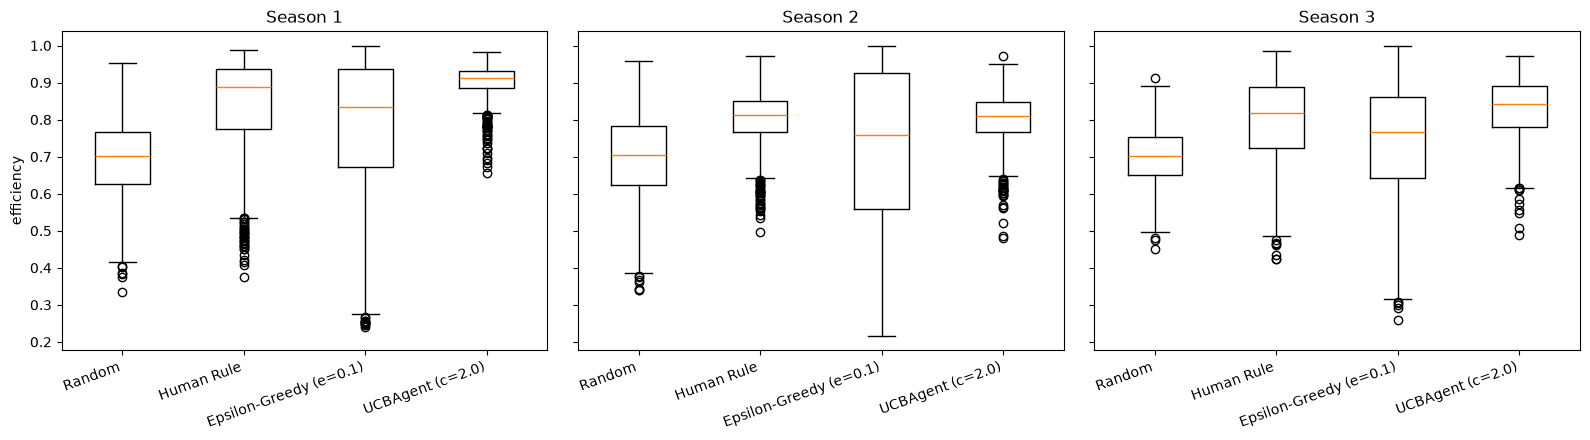

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, season in zip(axes, (1, 2, 3)):
    names = list(results_s1[season])
    ax.boxplot([[m["eta"] for m in results_s1[season][n]] for n in names])
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_title(f"Season {season}")
axes[0].set_ylabel("efficiency")
plt.tight_layout(); plt.show()

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [8]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)

team_comparison = []

for log in logs:
    player_name = log["student_id"]
    for season in (1, 2, 3):
        bay = FishingBay.from_log(log, season=season)
        p_spots, p_catches = choices(log, season=season)
        p_metrics = metrics(bay, p_spots, p_catches)

        human_eta = p_metrics["eta"] / 100.0 if p_metrics["eta"] > 1.0 else p_metrics["eta"]

        team_comparison.append({
            "Player": player_name,
            "Season": season,
            "Strategy": player_name,
            "Actual (kg)": round(p_metrics["actual"], 1),
            "Expected (kg)": round(p_metrics["E"], 1),
            "Luck (kg)": f"{p_metrics['luck']:+.1f}",
            "Best Possible (kg)": round(p_metrics["V*"], 1),
            "Efficiency": round(human_eta, 3),
            "Pseudo-Regret (kg)": round(p_metrics["R_T"], 1),
        })

        agents = {
                # "Random": RandomAgent(seed=0),
                "Human Rule": HumanRuleAgent(horizon=bay.days, seed=0),
                "Epsilon-Greedy (e=0.1)": EpsilonGreedyAgent(epsilon=0.1, alpha=None, seed=0),
                "UCBAgent (c=2.0)": UCBAgent(c=2.0, seed=0)
            }

        for agent_name, agent in agents.items():
            m = play_and_measure(agent, bay)
            agent_eta = m["eta"] / 100.0 if m["eta"] > 1.0 else m["eta"]
            team_comparison.append({
                "Player": player_name,
                "Season": season,
                "Strategy": agent_name,
                "Actual (kg)": round(m["actual"], 1),
                "Expected (kg)": round(m["E"], 1),
                "Luck (kg)": f"{m['luck']:+.1f}",
                "Best Possible (kg)": round(m["V*"], 1),
                "Efficiency": round(agent_eta, 3),
                "Pseudo-Regret (kg)": round(m["R_T"], 1),
            })

df_team = pd.DataFrame(team_comparison)
print(df_team.to_string(index=False))

Player  Season               Strategy  Actual (kg)  Expected (kg) Luck (kg)  Best Possible (kg)  Efficiency  Pseudo-Regret (kg)
  ioni       1                   ioni        198.2          205.6      -7.4               246.0       0.836                40.4
  ioni       1             Human Rule        190.5          192.2      -1.7               246.0       0.781                53.8
  ioni       1 Epsilon-Greedy (e=0.1)        224.5          222.3      +2.2               246.0       0.904                23.7
  ioni       1       UCBAgent (c=2.0)        223.3          224.3      -1.0               246.0       0.912                21.7
  ioni       2                   ioni         56.2           56.7      -0.5                97.0       0.585                40.3
  ioni       2             Human Rule         78.5           71.2      +7.3                97.0       0.734                25.8
  ioni       2 Epsilon-Greedy (e=0.1)         69.8           79.2      -9.4                97.0       0.

For a single run of the agents with seed = 0, we coonclude:

* Luck against decisions:
    * Season 2 -> `Human Rule` and `UCB` and `kimj` have the same performance, the difference stay in the luck each had. 
    * Season 3 -> `Human Rule` caughat 230.4 kg against `kimj` - 218 kg. The difference comes from the 12 kg of `luck` that the `Human Rule` had, while `kimj` had only 0.8 kg of `luck`.
    * Season 3 -> `Human Rule` caughat 174.8 kg against `ioni` - 197.4 kg. The difference comes from the -35.6 kg of bad `luck` that the `Human Rule` had, while `ioni` had -13.4 kg of bad `luck`. 

* In Season 1 the agents performed better then the actual players, with one exception being between `ioni` and the `Human Rule`. 
* In Season 2 the agents and the players had a similar performance, except `ioni` who applied the same strategy as in the longer seasons and waited time exploring. Her performance is the weakest. `kimj` and `szabo` committed after one pass, which made them have an efficiency similar with the one of the agents. 
* In Season 3, `ioni` and `kimj` have a similar performance. `szabo` adapted faster then the agents. 

In [9]:
N_SEEDS = 100        # agent seeds per (player, season)
team_comparison = []

for log in logs:
    player_name = log["student_id"]
    for season in (1, 2, 3):
        bay = FishingBay.from_log(log, season=season)          
        p_spots, p_catches = choices(log, season=season)
        p_metrics = metrics(bay, p_spots, p_catches)
        human_eta = p_metrics["eta"]

        # the player: one real season
        team_comparison.append({
            "Player": player_name,
            "Season": season,
            "Strategy": player_name,
            # "Actual (kg)": round(p_metrics["actual"], 1),
            # "Expected (kg)": round(p_metrics["E"], 1),
            # "Luck (kg)": f"{p_metrics['luck']:+.1f}",
            # "Best Possible (kg)": round(p_metrics["V*"], 1),
            # "Efficiency": round(human_eta, 3),
            # "Efficiency SD": "-",
            # "Pseudo-Regret (kg)": round(p_metrics["R_T"], 1),
            "P(agent > player)": "-",
        })

        # a new agent is created for every seed (the agents are random)
        agent_makers = {
            "Human Rule": lambda s: HumanRuleAgent(horizon=bay.days, seed=s),
            "Epsilon-Greedy (e=0.1)": lambda s: EpsilonGreedyAgent(epsilon=0.1, alpha=None, seed=s),
            "UCBAgent (c=2.0)": lambda s: UCBAgent(c=2.0, seed=s),
        }

        for agent_name, make in agent_makers.items():
            runs = [play_and_measure(make(s), bay) for s in range(N_SEEDS)]
            etas = np.array([m["eta"] for m in runs])
            team_comparison.append({
                "Player": player_name,
                "Season": season,
                "Strategy": agent_name,
                # "Actual (kg)": round(np.mean([m["actual"] for m in runs]), 1),
                # "Expected (kg)": round(np.mean([m["E"] for m in runs]), 1),
                # "Luck (kg)": f"{np.mean([m['luck'] for m in runs]):+.1f}",
                # "Best Possible (kg)": round(runs[0]["V*"], 1),
                # "Efficiency": round(etas.mean(), 3),
                # "Efficiency SD": round(etas.std(), 3),
                # "Pseudo-Regret (kg)": round(np.mean([m["R_T"] for m in runs]), 1),
                "P(agent > player)": round(np.mean(etas > human_eta), 2),
            })

df_team = pd.DataFrame(team_comparison)
print(df_team.to_string(index=False))

Player  Season               Strategy P(agent > player)
  ioni       1                   ioni                 -
  ioni       1             Human Rule              0.33
  ioni       1 Epsilon-Greedy (e=0.1)              0.54
  ioni       1       UCBAgent (c=2.0)              0.84
  ioni       2                   ioni                 -
  ioni       2             Human Rule              0.87
  ioni       2 Epsilon-Greedy (e=0.1)              0.51
  ioni       2       UCBAgent (c=2.0)               0.9
  ioni       3                   ioni                 -
  ioni       3             Human Rule              0.62
  ioni       3 Epsilon-Greedy (e=0.1)              0.51
  ioni       3       UCBAgent (c=2.0)              0.98
  kimj       1                   kimj                 -
  kimj       1             Human Rule              0.68
  kimj       1 Epsilon-Greedy (e=0.1)               0.7
  kimj       1       UCBAgent (c=2.0)              0.86
  kimj       2                   kimj           

The table above shows the results of multiple agents created with different seeds (from 0 to 99) playing on the player's bays. The last column, `P(agent > player)` shows the share of runs in which the agent performs better than the human player. 

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [10]:
# rank agents on standard Season 2 and Season 3
for season in (2, 3):
    days = FishingBay(season=season, seed=0).days
    print(f"\n{'='*95}")
    print(f"Season {season} ({days} days) Ranking - Over {N_BAYS} Random Bays")

    ranking = []
    for name, ms in results_s1[season].items():
        df_m = pd.DataFrame(ms)
        eta_ratio = df_m["eta"] / 100.0 if df_m["eta"].mean() > 1.0 else df_m["eta"]
        ranking.append({
            "Agent": name,
            "Efficiency Mean (SD)": f"{eta_ratio.mean():.3f} ({eta_ratio.std():.3f})",
            "Pseudo-Regret Mean (SD)": f"{df_m['R_T'].mean():.1f} ({df_m['R_T'].std():.1f})",
            "_eta": eta_ratio.mean(),
        }) 
    df_rank = pd.DataFrame(ranking).sort_values("_eta", ascending=False).drop(columns=["_eta"])
    print(df_rank.to_string(index=False))

# experiment with longer season (200 days, shift at day 101)
N_EXT_BAYS = 500
ext_days, ext_shift = 200, 101

ext_agents = {
    "Human Rule": HumanRuleAgent(horizon=ext_days, seed=0),
    "Epsilon-Greedy (e=0.1)": EpsilonGreedyAgent(epsilon=0.1, alpha=None, seed=0),
    "UCBAgent (c=2.0)": UCBAgent(c=2.0, seed=0)
}

# track day by day efficiency before and after the shift
daily_eff = {name: np.zeros(ext_days) for name in ext_agents}
ext_summary = {name: [] for name in ext_agents}

for seed in range(N_EXT_BAYS):
    bay = FishingBay(season=3, seed=seed, days=ext_days, shift_day=ext_shift)
    mu_by_day = true_means_by_day(bay, ext_days)
    best_by_day = np.array([max(m) for m in mu_by_day])

    for name, agent in ext_agents.items():
        m = play_and_measure(agent, bay)
        ext_summary[name].append(m)
        chosen_spots = [s for s, _ in bay.history]
        chosen_means = np.array([mu_by_day[t][a] for t, a in enumerate(chosen_spots)])
        daily_eff[name] += (chosen_means / best_by_day) / N_EXT_BAYS

print(f"\n{'='*75}")
print(f"Extended Season 3 ({ext_days} days, shift at Day {ext_shift}) — Over {N_EXT_BAYS} Bays")

ext_rows = []

for name, ms in ext_summary.items():
    df_m = pd.DataFrame(ms)
    eta_ratio = df_m["eta"] / 100.0 if df_m["eta"].mean() > 1.0 else df_m["eta"]
    ext_rows.append({
        "Agent": name,
        "Efficiency Mean (SD)": f"{eta_ratio.mean():.3f} ({eta_ratio.std():.3f})",
        "Pseudo-Regret Mean (SD)": f"{df_m['R_T'].mean():.1f} ({df_m['R_T'].std():.1f})",
    })

print(pd.DataFrame(ext_rows).to_string(index=False))




Season 2 (10 days) Ranking - Over 1000 Random Bays
                 Agent Efficiency Mean (SD) Pseudo-Regret Mean (SD)
            Human Rule        0.802 (0.072)              17.2 (6.6)
      UCBAgent (c=2.0)        0.802 (0.067)              17.2 (6.3)
Epsilon-Greedy (e=0.1)        0.729 (0.217)             23.8 (19.8)
                Random        0.698 (0.117)             26.5 (11.3)

Season 3 (30 days) Ranking - Over 1000 Random Bays
                 Agent Efficiency Mean (SD) Pseudo-Regret Mean (SD)
      UCBAgent (c=2.0)        0.831 (0.078)             43.8 (20.5)
            Human Rule        0.799 (0.109)             52.2 (28.8)
Epsilon-Greedy (e=0.1)        0.747 (0.149)             66.0 (39.7)
                Random        0.699 (0.075)             78.4 (21.3)

Extended Season 3 (200 days, shift at Day 101) — Over 500 Bays
                 Agent Efficiency Mean (SD) Pseudo-Regret Mean (SD)
            Human Rule        0.774 (0.111)           390.0 (196.9)
Epsilon-Greedy (

* In Season 2, `Human Rule` and `UCB` have a similar performance in efficiency and regret. Both agents perform well in a 10-day season. 
* In Season 3, `UCB` has a better performance.  
* In the extended Season, `UCB` has the best performance before the change on day 101. It has a drop with the change, but then it adapts slowly and mantains the first position in performance. 
* In the extended Season, `Human Rule` agent adapts as well after the change, but it never settles. In a long season its stay rule leaves a good spot every few dozen days because of noise and resamples a stale spot. This explains why the performance of the agent decreases with the length of the season. 

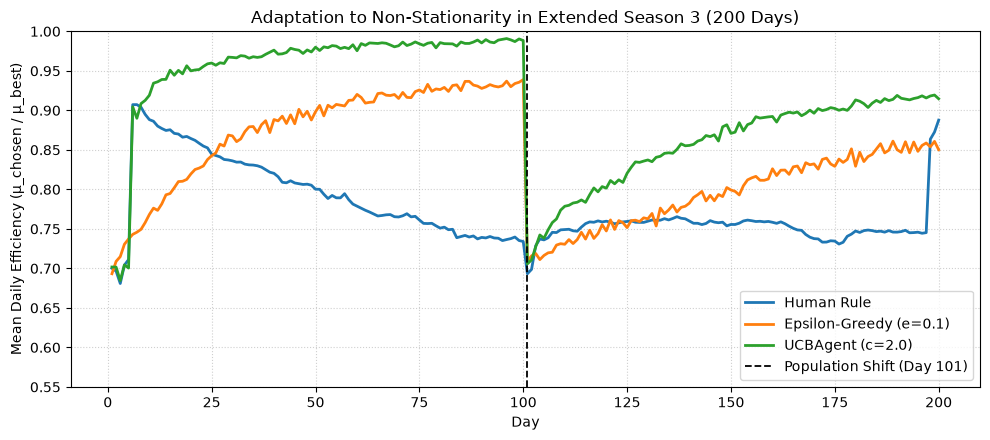

In [11]:
# Plot adaptation curve around the shift day
plt.figure(figsize=(10, 4.5))
days_axis = np.arange(1, ext_days + 1)
for name, curve in daily_eff.items():
    plt.plot(days_axis, curve, linewidth=2, label=name)

plt.axvline(ext_shift, color="black", linestyle="--", linewidth=1.3, label=f"Population Shift (Day {ext_shift})")
plt.title(f"Adaptation to Non-Stationarity in Extended Season 3 ({ext_days} Days)")
plt.xlabel("Day")
plt.ylabel("Mean Daily Efficiency (μ_chosen / μ_best)")
plt.ylim(0.55, 1.0)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. One parameter

Study the effect of one parameter of one method.


Season 1 (30 days) — UCBAgent Parameter Study over 1000 Random Bays
   c Actual Mean (SD) Expected Mean (SD) Efficiency Mean (SD) Regret Mean (SD)
0.00     235.9 (38.4)       235.9 (36.0)        0.907 (0.070)      24.1 (18.5)
0.25     236.7 (37.5)       236.4 (35.4)        0.909 (0.061)      23.6 (15.6)
0.50     237.1 (36.1)       237.1 (34.2)        0.912 (0.054)      22.9 (14.3)
1.00     236.3 (36.1)       236.2 (34.7)        0.908 (0.054)      23.8 (13.8)
1.50     236.4 (36.1)       236.1 (34.2)        0.907 (0.048)      23.9 (12.4)
2.00     235.9 (36.1)       235.0 (34.1)        0.903 (0.045)      25.0 (11.3)
3.00     232.4 (35.0)       231.6 (33.4)        0.890 (0.041)      28.4 (10.6)
4.00     227.4 (34.8)       227.5 (33.4)        0.874 (0.041)      32.5 (10.5)
6.00     219.3 (34.8)       218.5 (33.1)        0.839 (0.049)      41.4 (12.5)

Season 2 (10 days) — UCBAgent Parameter Study over 1000 Random Bays
   c Actual Mean (SD) Expected Mean (SD) Efficiency Mean (SD) Regret Mea

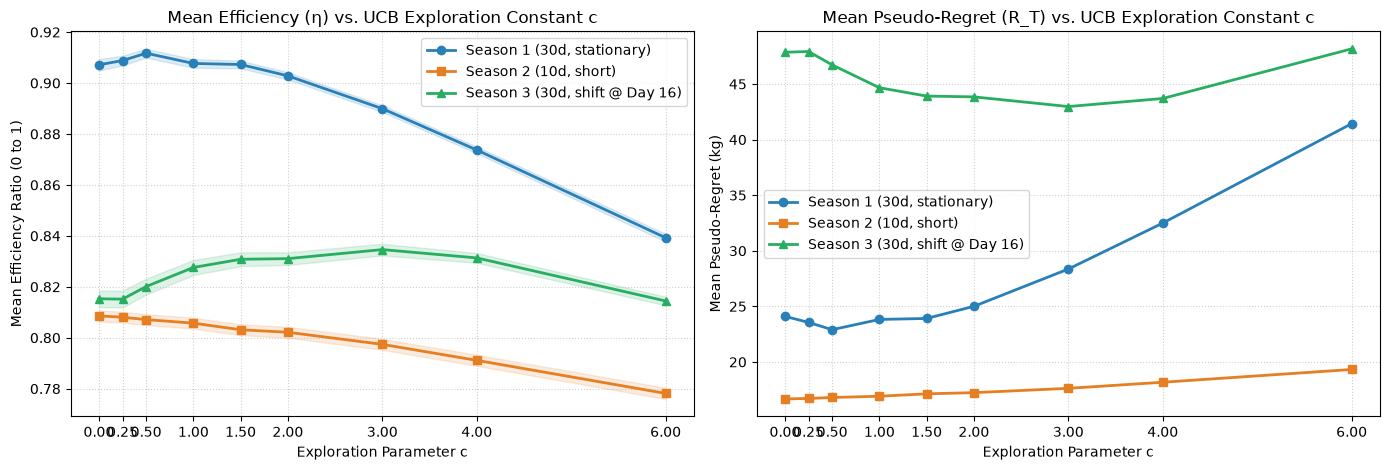

In [12]:
c_values = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]
N_PARAM_BAYS = 1000
param_records = {season: {} for season in (1, 2, 3)}

for season in (1, 2, 3):
    bay = FishingBay(season=season, seed=0)
    print(f"\n{'='*95}")
    print(f"Season {season} ({bay.days} days) — UCBAgent Parameter Study over {N_PARAM_BAYS} Random Bays")

    rows = []
    for c in c_values:
        agent = UCBAgent(c=c, seed=0)
        ms = []
        for seed in range(N_PARAM_BAYS):
            bay = FishingBay(season=season, seed=seed)
            ms.append(play_and_measure(agent, bay))

        param_records[season][c] = ms
        df_m = pd.DataFrame(ms)
        eta_ratio = df_m["eta"] / 100.0 if df_m["eta"].mean() > 1.0 else df_m["eta"]

        rows.append({
            "c": c,
            "Actual Mean (SD)": f"{df_m['actual'].mean():.1f} ({df_m['actual'].std():.1f})",
            "Expected Mean (SD)": f"{df_m['E'].mean():.1f} ({df_m['E'].std():.1f})",
            "Efficiency Mean (SD)": f"{eta_ratio.mean():.3f} ({eta_ratio.std():.3f})",
            "Regret Mean (SD)": f"{df_m['R_T'].mean():.1f} ({df_m['R_T'].std():.1f})",
        })

    print(pd.DataFrame(rows).to_string(index=False))

# plot efficiency & pseudo-regret vs. exploration parameter c
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
season_styles = {
    1: ("Season 1 (30d, stationary)", "#2980b9", "o"),
    2: ("Season 2 (10d, short)", "#e67e22", "s"),
    3: ("Season 3 (30d, shift @ Day 16)", "#27ae60", "^"),
}

for season, (label, color, marker) in season_styles.items():
    means_eta = []
    sds_eta = []
    means_regret = []

    for c in c_values:
        df_m = pd.DataFrame(param_records[season][c])
        eta_ratio = df_m["eta"]
        means_eta.append(eta_ratio.mean())
        sds_eta.append(eta_ratio.std())
        means_regret.append(df_m["R_T"].mean())

    means_eta = np.array(means_eta)
    se_eta = np.array(sds_eta) / np.sqrt(N_PARAM_BAYS) # standard error of the mean

    ax1.plot(c_values, means_eta, marker=marker, linewidth=2, color=color, label=label)
    ax1.fill_between(c_values, means_eta - se_eta, means_eta + se_eta, color=color, alpha=0.15)
    ax2.plot(c_values, means_regret, marker=marker, linewidth=2, color=color, label=label)

ax1.set_title("Mean Efficiency (η) vs. UCB Exploration Constant c")
ax1.set_xlabel("Exploration Parameter c")
ax1.set_ylabel("Mean Efficiency Ratio (0 to 1)")
ax1.set_xticks(c_values)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

ax2.set_title("Mean Pseudo-Regret (R_T) vs. UCB Exploration Constant c")
ax2.set_xlabel("Exploration Parameter c")
ax2.set_ylabel("Mean Pseudo-Regret (kg)")
ax2.set_xticks(c_values)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

* In Season 1 we can see that the best performance is for `c <= 2` (0.903 to 0.912), and it decreases for `c >=3` (0.839).
* In season 2, the efficiency decreases with the increase of `c`. We can say that exploration is a loss in short seasons. 
* In Season 3, the performance is better when `c` is between 1.5 and 4 (0.831 to 0.835). The efficiency decreases when `c` takes too small or to high values. We can say that with no exploration, the agent cannot notice the change, and with too much it wastes days. 
* In conclusion, the best level of exploration depends on the season.  

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [13]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")



Random contextual agent: 1945.7 kg over 300 days


### 5-1: predicting the catch from the conditions

We compare five agents on the same 200 contextual bays (seeds 0 to 199, 300 days each), with the metric of Part II adapted to this bay: **Efficiency (η) = Expected catch (E[Catch]) / Best possible catch (V\*)**, where V\* now adds up the best spot of **each day** (it is `bay.best_possible()`). The agents are defined in `agents.py`:

* `RandomContextualAgent`: lower baseline.
* `ContextFreeUCBAgent`: the best agent of Part III (`UCB`, `c = 2.0`), which ignores the conditions.
* `LinearGreedyAgent`: linear regression per spot, always goes to the highest prediction (acts only on the predictions).
* `LinearEpsilonGreedyAgent` with `epsilon = 0.05` and `0.1`: the same agent with epsilon-exploration (the fix).


In [14]:
# --- Task 6, cell 1: metric adapted to the contextual bay, and the agents compared ---
# ContextualBay.reveal() returns a (days x 5) table of true means and history stores
# (conditions, spot, catch), so the Part III metric is rewritten here with the same meaning.

N_CTX_BAYS = 200     # contextual bays per agent (300 days each)

def contextual_metrics(bay):
    mu = bay.reveal()                                  # true mean table, days x 5
    spots = [s for _, s, _ in bay.history]
    catches = [c for _, _, c in bay.history]
    expected = float(sum(mu[t, a] for t, a in enumerate(spots)))   # Expected catch (E[Catch])
    v_star = float(bay.best_possible())                # Best possible catch (V*): best spot of each day
    actual = float(sum(catches))                       # Actual catch
    return {"actual": actual, "E": expected, "luck": actual - expected,
            "V*": v_star, "eta": expected / v_star, "R_T": v_star - expected}


def play_and_measure(agent, bay):
    play(agent, bay)
    return contextual_metrics(bay)


def make_agents(seed):
    return {
        "Random": RandomContextualAgent(seed=seed),
        "UCB (best agent of Part III)": ContextFreeUCBAgent(c=2.0, seed=seed),
        "Linear Greedy (predictions only)": LinearGreedyAgent(seed=seed),
        "Linear + eps=0.05 (the fix)": LinearEpsilonGreedyAgent(epsilon=0.05, seed=seed),
        "Linear + eps=0.1 (the fix)": LinearEpsilonGreedyAgent(epsilon=0.1, seed=seed),
    }

In [15]:
# --- Task 6, cell 2: all agents on the same contextual bays ---
print("=" * 108)
print(f"PART A: average over {N_CTX_BAYS} contextual bays (seeds 0-{N_CTX_BAYS - 1}, 300 days each); in brackets: standard deviation")
print("=" * 108)
ctx_rows = {name: [] for name in make_agents(0)}
for seed in range(N_CTX_BAYS):
    bay = ContextualBay(seed=seed)
    for name, agent in make_agents(seed).items():
        ctx_rows[name].append(play_and_measure(agent, bay))

COLS = [("actual", "Actual catch (kg)"), ("luck", "Luck (L, kg)"),
        ("eta", "Efficiency (eta, %)"), ("R_T", "Pseudo-regret (R_T, kg)")]
print(f"{'Agent':34s}" + "".join(f"{c:>26s}" for _, c in COLS))
arrs = {}
for name, ms in ctx_rows.items():
    arr = {k: np.array([m[k] for m in ms]) for k in ms[0]}
    arrs[name] = arr
    cells = []
    for key, _ in COLS:
        f = (lambda v: f"{v*100:.2f}") if key == "eta" else (lambda v: f"{v:.1f}")
        cells.append(f"{f(arr[key].mean())} ({f(arr[key].std())})")
    print(f"{name:34s}" + "".join(f"{c:>26s}" for c in cells))

g, u = arrs["Linear Greedy (predictions only)"]["eta"], arrs["UCB (best agent of Part III)"]["eta"]
f5 = arrs["Linear + eps=0.05 (the fix)"]["eta"]
print(f"\n  Linear Greedy beats the context-free UCB in {np.mean(g > u)*100:.1f}% of bays; "
      f"the eps=0.05 fix beats UCB in {np.mean(f5 > u)*100:.1f}% of bays.")
print(f"  The fix (eps=0.05) beats Linear Greedy in {np.mean(f5 > g)*100:.1f}% of bays.")
print(f"  Worst bay efficiency: Linear Greedy {g.min()*100:.1f}%, fix {f5.min()*100:.1f}%, UCB {u.min()*100:.1f}%.")
print(f"  5th-percentile efficiency: Linear Greedy {np.percentile(g,5)*100:.1f}%, "
      f"fix {np.percentile(f5,5)*100:.1f}%, UCB {np.percentile(u,5)*100:.1f}%.")

PART A: average over 200 contextual bays (seeds 0-199, 300 days each); in brackets: standard deviation
Agent                                      Actual catch (kg)              Luck (L, kg)       Efficiency (eta, %)   Pseudo-regret (R_T, kg)
Random                                        1767.8 (381.7)               45.9 (49.2)              56.85 (9.38)            1313.3 (398.9)
UCB (best agent of Part III)                  2853.9 (637.1)                2.8 (42.7)              93.35 (6.13)             183.9 (156.9)
Linear Greedy (predictions only)              2884.8 (561.6)                4.3 (42.0)              94.74 (1.69)              154.6 (39.1)
Linear + eps=0.05 (the fix)                   2831.2 (548.3)                6.2 (42.2)              92.93 (1.82)              210.1 (49.8)
Linear + eps=0.1 (the fix)                    2777.1 (535.3)                8.9 (43.4)              91.08 (2.04)              266.9 (64.5)

  Linear Greedy beats the context-free UCB in 45.5% of bays; t

### Comparison with the best agent of Part III

* `Linear Greedy` fits, for each spot, a linear regression of the catch on the morning conditions (`catch ~ a + b*wind + c*waves + d*tide`) and goes to the spot with the highest prediction. The linear model fits this bay well: the true mean of each spot is a linear function of the conditions, clipped at 0.
* `UCB (context-free)` is the best agent of Part III (`UCB`, `c = 2.0`). It receives the conditions but ignores them. We had to write it as a `ContextualAgent` because `play()` refuses a plain `Agent` on a `ContextualBay`.
* On average, using the conditions helps a little: `Linear Greedy` reaches 94.74% efficiency against 93.35% for `UCB` (about +1.4 points, or 29 kg less regret over 300 days). It beats `UCB` in only 45.5% of the bays, so the average gain is small.
* The bigger gain is stability. The standard deviation of the efficiency is 1.69 for `Linear Greedy` against 6.13 for `UCB`. In the worst bay `Linear Greedy` still reaches 86.5%, while `UCB` falls to 71.6% (5th percentile: 91.5% against 80.2%).
* Why the average gap is small: the best spot changes from day to day with the conditions, but in most bays one spot stays good on most days. Always fishing the best single spot of a bay already reaches 95.4% of the best possible on average (over the same 200 bays). The efficiency of `UCB` follows this value closely (correlation 0.87 across the bays), so `UCB` mostly fails on the bays where no single spot is good on most days.
* `Random` (56.85%) is the lower baseline. The `Luck` column is close to 0 for every agent, so the differences in efficiency come from the decisions and not from luck.


In [16]:
# --- Task 6, cell 3: a case where acting only on the predictions fails ---
print("=" * 108)
print("PART B: the failure case of 'predictions only' (and what the fix does on the same bay)")
print("=" * 108)
worst = int(np.argmin(g))
print(f"Worst bay for Linear Greedy: seed {worst} "
      f"(efficiency {g[worst]*100:.1f}%, vs fix {f5[worst]*100:.1f}%, UCB {u[worst]*100:.1f}%)")

bay = ContextualBay(seed=worst)
agent = LinearGreedyAgent(seed=worst)
play(agent, bay)
mu = bay.reveal()
spots = [s for _, s, _ in bay.history]
visits = np.bincount(spots, minlength=5)
best_days = np.bincount(mu.argmax(axis=1), minlength=5)
print(f"\n{'Spot':>4s} {'Days it was truly the best':>27s} {'Days the agent went there':>26s} "
      f"{'True mean catch, season average (kg)':>37s}")
for k in range(5):
    print(f"{k:>4d} {best_days[k]:>27d} {visits[k]:>26d} {mu[:, k].mean():>37.2f}")

neglected = int(np.argmax(best_days * (visits < 30)))
conds = np.array([[c["wind_kmh"], c["waves_m"], c["tide_m"]] for c, _, _ in bay.history])
pred = np.array([agent._predict(neglected, x) for x in conds])
print(f"\nThe neglected spot is Spot {neglected}: truly the best on {best_days[neglected]} of 300 days, "
      f"visited only {visits[neglected]} times (the {agent.n_init} initial visits plus a few days "
      f"when the model ranked it first or tied).")
print(f"Over the whole season, the agent's final model predicts on average {pred.mean():.2f} kg "
      f"for Spot {neglected}, while its true average is {mu[:, neglected].mean():.2f} kg.")
print(f"On the days when Spot {neglected} was truly the best, the model predicts on average "
      f"{pred[mu.argmax(axis=1) == neglected].mean():.2f} kg vs a true mean of "
      f"{mu[mu.argmax(axis=1) == neglected, neglected].mean():.2f} kg.")

fix = LinearEpsilonGreedyAgent(epsilon=0.05, seed=worst)
play(fix, bay)
fvisits = np.bincount([s for _, s, _ in bay.history], minlength=5)
fpred = np.array([fix._predict(neglected, x) for x in conds])
print(f"\nThe fix on the same bay: epsilon-exploration revisits Spot {neglected} {fvisits[neglected]} times, "
      f"its predicted season average becomes {fpred.mean():.2f} kg (true {mu[:, neglected].mean():.2f} kg), "
      f"efficiency {contextual_metrics(bay)['eta']*100:.1f}% vs {g[worst]*100:.1f}% without exploration.")

PART B: the failure case of 'predictions only' (and what the fix does on the same bay)
Worst bay for Linear Greedy: seed 184 (efficiency 86.5%, vs fix 90.8%, UCB 91.6%)

Spot  Days it was truly the best  Days the agent went there  True mean catch, season average (kg)
   0                           0                          5                                  0.61
   1                           6                        195                                  6.51
   2                          19                          6                                  3.55
   3                         188                         18                                  7.30
   4                          87                         76                                  5.82

The neglected spot is Spot 3: truly the best on 188 of 300 days, visited only 18 times (the 4 initial visits plus a few days when the model ranked it first or tied).
Over the whole season, the agent's final model predicts on average 3.42 kg 

### When acting only on the predictions fails, and a fix

* **The failure case.** In bay seed 184 (the worst bay for `Linear Greedy`), Spot 3 is truly the best spot on 188 of the 300 days, but the agent goes there only 18 times. It spends 195 days at Spot 1, which is the best on only 6 days. Its efficiency is 86.5%, lower than `UCB` (91.6%) on the same bay.
* **Why it fails.** At the end of the season, the model predicts on average 3.42 kg for Spot 3, while its true average is 7.30 kg (2.42 kg against 7.89 kg on the days when Spot 3 was the best). The first catches at Spot 3 were unlucky, so the regression learned a value that is too low. With a low prediction, Spot 3 is almost never chosen; without visits, no new data arrives, and the wrong prediction is never corrected. This is a feedback loop: the agent only gets data from the spots it chooses, and it chooses only from its predictions.
* **The fix: epsilon-exploration.** `LinearEpsilonGreedyAgent` is the same agent, except that on each day after the initial visits it goes to a random spot with probability `epsilon`. Every spot keeps receiving new data, so a wrong prediction can be corrected. On the same bay with `epsilon = 0.05`, it visits Spot 3 118 times, its prediction for Spot 3 rises to 6.96 kg (true 7.30 kg), and the efficiency goes from 86.5% to 90.8%.
* **The cost of the fix.** Exploration is not free: every random visit is a day spent away from the predicted best spot. Over the 200 bays, the fix has a lower average efficiency than `Linear Greedy` (92.93% for `epsilon = 0.05`, 91.08% for `epsilon = 0.1`, against 94.74%) and beats it in only 5.5% of the bays. Its worst bay (83.5%) is also lower than the worst bay of `Linear Greedy` (86.5%).
* **Conclusion.** In this bay, a bad start costs little on average, because most bays have one spot that is good on most days. Acting only on the predictions works well on average, but it can lock out a good spot after a few unlucky catches. Epsilon-exploration repairs this case at the cost of a lower average. A better fix would explore less as the data grows, for example a smaller `epsilon` that decreases over time, or an exploration bonus for spots whose prediction is uncertain (the idea of UCB applied to the regression).
